# Hardware constraints and toy models

Connectivity, routing cost and device noise on the 2D Heisenberg state and on a heavy-hex patch, followed by the GHZ depth result, a quantics Gaussian and a T-count example. Infidelity is $\varepsilon=1-|\langle\psi|C|0\rangle|$ with the free single-qubit frame. Blue is the MPD and orange is ASPIRE.

In [1]:
using Pkg; Pkg.activate(@__DIR__)

In [2]:
using ASPIRE, MPSCircuits, ITensors, ITensorMPS, Plots, Random, Printf
default(framestyle=:box, grid=false, legend=:best, size=(760, 340), linewidth=2, markersize=4,
    guidefontsize=10, tickfontsize=9, legendfontsize=8, left_margin=4Plots.mm, bottom_margin=4Plots.mm)
const BLUE, ORANGE = RGB(0.12, 0.40, 0.80), RGB(0.90, 0.45, 0.05)

(RGB{Float64}(0.12, 0.4, 0.8), RGB{Float64}(0.9, 0.45, 0.05))

## Connectivity radius

ASPIRE on the Heisenberg 4x3 state, restricted to pairs within chain distance $r$. Radius 1 is the reach of the MPD.

In [3]:
set_max_bond_dim!(64); set_cutoff!(1e-10)
psi_heis = heisenberg_snake_state(4, 3; nsweeps=6, rng=MersenneTwister(1))
N_heis = length(psi_heis)
@printf("N = %d, chi = %d, total correlation T = %.2f bits\n", N_heis, maxlinkdim(psi_heis), total_correlation(psi_heis))

budget = 60
radii = (1, 2, 3, 5, 7, 11)
aspire_curves = Dict{Int,Any}()
for r in radii
    cfg = ASPIREConfig(threshold=0.0, relative_threshold=0.0, max_depth=60, max_gates=budget,
        batch_mode=:matching, cost_normalised=false, accept_only=false, min_objective_gain=-1e6)
    run = aspire(psi_heis; config=cfg, pairs=candidate_pairs(N_heis; max_distance=r))
    aspire_curves[r] = (gates=run.gates, eps=run.product_frame_amplitude_infidelity)
end
mpd = ran_iter_oall_curve(psi_heis; Lmax=6, sweeps=0)
mpd_gates, mpd_eps = mpd.gates[2:end], 1 .- sqrt.(mpd.fid[2:end])

at_budget = [curve_infidelity_at(aspire_curves[r].gates, aspire_curves[r].eps, budget) for r in radii]
for (r, e) in zip(radii, at_budget); @printf("ASPIRE r = %-3d infidelity at %d gates: %.4f\n", r, budget, e); end
@printf("MPD (interpolated at %d gates): %.4f\n", budget, curve_infidelity_at(mpd_gates, mpd_eps, budget))

N = 12, chi = 64, total correlation T = 12.00 bits
ASPIRE r = 1   infidelity at 60 gates: 0.4479
ASPIRE r = 2   infidelity at 60 gates: 0.1576
ASPIRE r = 3   infidelity at 60 gates: 0.1122
ASPIRE r = 5   infidelity at 60 gates: 0.1727
ASPIRE r = 7   infidelity at 60 gates: 0.0974
ASPIRE r = 11  infidelity at 60 gates: 0.0937
MPD (interpolated at 60 gates): 0.1533


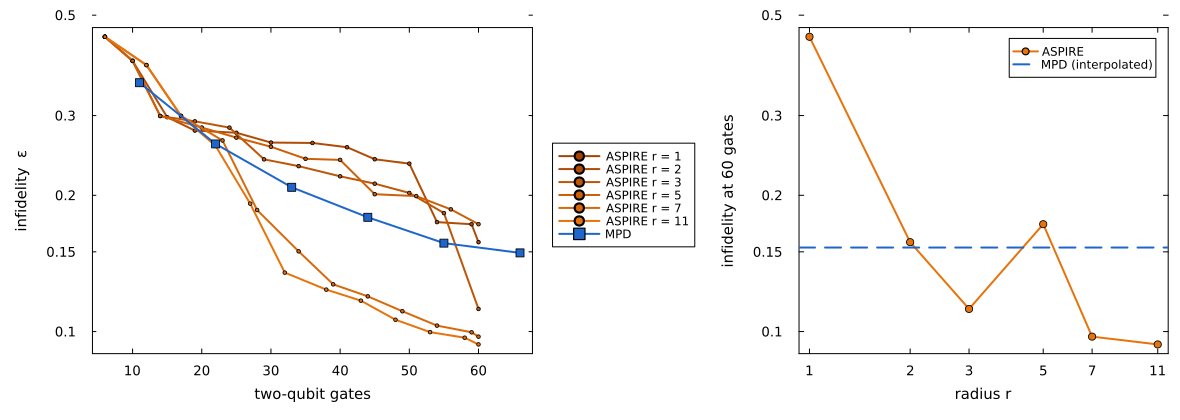

In [4]:
shade(r) = weighted_color_mean(0.25 + 0.75 * (findfirst(==(r), radii) - 1) / (length(radii) - 1), ORANGE, RGB(0.55, 0.2, 0.0))
ticks = ([0.1, 0.15, 0.2, 0.3, 0.5, 0.7], ["0.1", "0.15", "0.2", "0.3", "0.5", "0.7"])
pl = plot(xlabel="two-qubit gates", ylabel="infidelity  ε", yscale=:log10, yticks=ticks, legend=:outerright)
for r in radii
    c = aspire_curves[r]
    plot!(pl, c.gates[2:end], c.eps[2:end]; color=shade(r), linestyle=(r == 1 ? :dash : :solid),
        marker=:circle, markersize=2, label="ASPIRE r = $r")
end
plot!(pl, mpd_gates, mpd_eps; color=BLUE, marker=:square, label="MPD")
pr = plot(xlabel="radius r", ylabel="infidelity at $budget gates", yscale=:log10, yticks=ticks, xscale=:log10,
    xticks=([1, 2, 3, 5, 7, 11], string.([1, 2, 3, 5, 7, 11])), legend=:topright)
plot!(pr, collect(radii), at_budget; color=ORANGE, marker=:circle, label="ASPIRE")
hline!(pr, [curve_infidelity_at(mpd_gates, mpd_eps, budget)]; color=BLUE, linestyle=:dash, label="MPD (interpolated)")
plot(pl, pr; layout=grid(1, 2, widths=[0.62, 0.38]), size=(1180, 420), left_margin=8Plots.mm, bottom_margin=9Plots.mm, top_margin=5Plots.mm)

## Routing cost on the running layout

A gate on sites at layout distance $d$ needs $d-1$ SWAPs and costs $3d$ CNOTs. On the running layout the permutation left by the SWAPs is kept, and later gates are priced on the new layout. Worked example on a line of six qubits.

In [5]:
line = [(i, i + 1) for i in 1:5]
tables = graph_routing_tables(6, line)
layout = RoutingLayout(6)
gate_list = [(1, 4), (1, 4), (2, 5), (1, 6)]
total_cnots = 0
for (i, j) in gate_list
    d = layout_distance(layout, tables.distances, i, j)
    cost_unit = route_gate!(layout, tables.distances, tables.predecessors, i, j)
    cnots = 3 * (1 + (d - 1))
    global total_cnots += cnots
    @printf("gate (%d,%d): distance %d, SWAPs %d, %2d CNOTs  [unit cost %2d]  -> qubit_at = %s\n",
        i, j, d, d - 1, cnots, cost_unit, layout.qubit_at)
end
println("total: ", total_cnots, " CNOTs; routed_layer_cost! gives ",
    routed_layer_cost!(RoutingLayout(6), tables, gate_list; gate_cost=3))
println("same gates priced on the pristine layout, CNOTs: ",
    [gate_cost(tables.distances[i, j]; convention=:no_restore) + 2 for (i, j) in gate_list])

gate (1,4): distance 3, SWAPs 2,  9 CNOTs  [unit cost  7]  -> qubit_at = [2, 3, 1, 4, 5, 6]
gate (1,4): distance 1, SWAPs 0,  3 CNOTs  [unit cost  1]  -> qubit_at = [2, 3, 1, 4, 5, 6]
gate (2,5): distance 4, SWAPs 3, 12 CNOTs  [unit cost 10]  -> qubit_at = [3, 1, 4, 2, 5, 6]
gate (1,6): distance 4, SWAPs 3, 12 CNOTs  [unit cost 10]  -> qubit_at = [3, 4, 2, 5, 1, 6]
total: 36 CNOTs; routed_layer_cost! gives 36
same gates priced on the pristine layout, CNOTs: [9, 9, 9, 15]


Cost of one MPD staircase layer (N - 1 logical gates) on the two-hexagon heavy-hex patch for three MPS orderings.

In [6]:
for ordering in (:rowmajor, :snake, :routing)
    patch = heavy_hex_patch(2; ordering=ordering)
    N = length(patch.coordinates)
    @printf("%-9s N = %d, couplers = %d: staircase layer costs %3d native gates (running), %3d (restore); N-1 = %d\n",
        ordering, N, length(patch.pairs), staircase_cost(N, patch.pairs),
        staircase_cost(N, patch.pairs; convention=:restore), N - 1)
end

rowmajor  N = 21, couplers = 22: staircase layer costs 245 native gates (running), 440 (restore); N-1 = 20
snake     N = 21, couplers = 22: staircase layer costs 128 native gates (running), 224 (restore); N-1 = 20
routing   N = 21, couplers = 22: staircase layer costs  20 native gates (running),  20 (restore); N-1 = 20


## Heavy-hex patch under global depolarising noise

Kicked transverse-field Ising state on the two-hexagon patch ($N=21$, 22 couplers). ASPIRE is restricted to device couplers, so every gate is native. The MPD is charged 1.4 native gates per logical gate. Both arms are refit by two Procrustes sweeps at each checkpoint. With a two-qubit depolarising channel of strength $p$ after every native gate, $F=qF_0+(1-q)2^{-N}$ with $q=(1-16p/15)^M$ for $M$ native gates. Stars mark the best stopping point.

In [7]:
set_max_bond_dim!(64); set_cutoff!(1e-12)
patch = heavy_hex_patch(2)
N_hh = length(patch.coordinates)
psi_hh = graph_kicked_ising_state(N_hh, patch.pairs; theta_h=0.4, steps=2)
@printf("N = %d, couplers = %d, chi = %d, T = %.2f bits\n", N_hh, length(patch.pairs), maxlinkdim(psi_hh), total_correlation(psi_hh))

cfg_hh = ASPIREConfig(threshold=0.0, relative_threshold=0.0, max_depth=60, batch_mode=:matching,
    shortlist=32, matching_max_edges=48, cost_normalised=false, pair_gate_cost=1)
aspire_cp = aspire_checkpoints(psi_hh, cfg_hh; pairs=patch.pairs, sweeps=2, gate_budget=60, checkpoint_interval=2)
mpd_cp = mpd_checkpoints(psi_hh; layers=3, sweeps=2)

aspire_logical = [r.two_qubit_gates for r in aspire_cp]
mpd_logical = [r.two_qubit_gates for r in mpd_cp]
aspire_native = aspire_logical
mpd_native = [native_gate_count(g; swaps_per_gate=MPD_SWAPS_PER_GATE) for g in mpd_logical]
println("ASPIRE checkpoints (gates): ", aspire_logical)
println("MPD checkpoints (logical -> native): ", collect(zip(mpd_logical, mpd_native)))
@printf("noiseless eps: ASPIRE %.2e at %d gates, MPD %.2e at %d gates\n",
    1 - sqrt(aspire_cp[end].squared_fidelity), aspire_logical[end], 1 - sqrt(mpd_cp[end].squared_fidelity), mpd_logical[end])

N = 21, couplers = 22, chi = 16, T = 1.86 bits
ASPIRE checkpoints (gates): [0, 19, 32, 42, 52, 58, 60]
MPD checkpoints (logical -> native): [(0, 0), (20, 28), (40, 56), (60, 84)]
noiseless eps: ASPIRE 3.67e-03 at 60 gates, MPD 1.77e-03 at 60 gates


p = 1e-04   min eps @ gates:  ASPIRE 5.96e-03 @ 32    MPD (1.4x) 6.23e-03 @ 84    MPD (uncharged) 4.96e-03 @ 60 
p = 2e-04   min eps @ gates:  ASPIRE 7.66e-03 @ 32    MPD (1.4x) 1.00e-02 @ 56    MPD (uncharged) 8.14e-03 @ 60 
p = 1e-03   min eps @ gates:  ASPIRE 2.00e-02 @ 19    MPD (1.4x) 2.18e-02 @ 28    MPD (uncharged) 1.76e-02 @ 20 


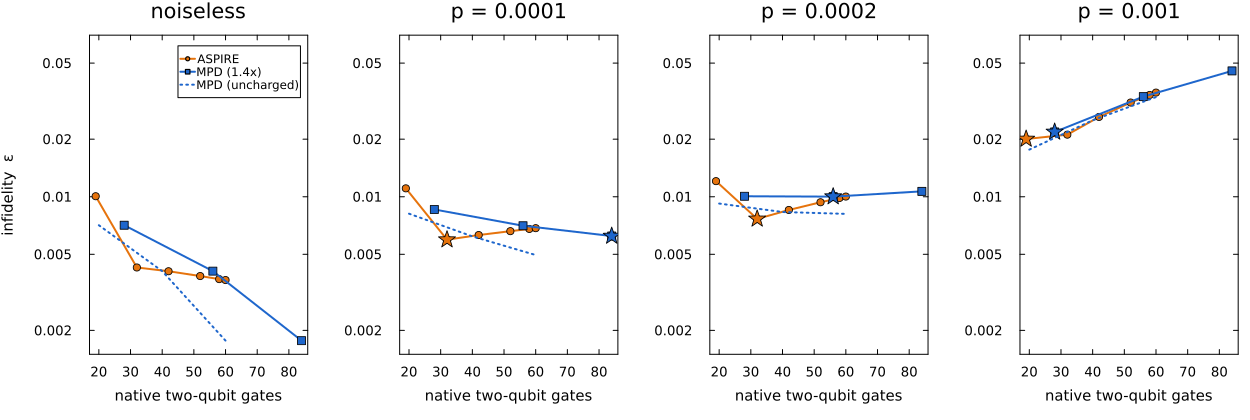

In [8]:
noise_eps(cps, native, p) = [global_depolarizing_infidelity(c.squared_fidelity, m, p, N_hh) for (c, m) in zip(cps, native)]
rates = (1e-4, 2e-4, 1e-3)
yt = ([0.002, 0.005, 0.01, 0.02, 0.05], ["0.002", "0.005", "0.01", "0.02", "0.05"])
panels = []
pn = plot(title="noiseless", xlabel="native two-qubit gates", ylabel="infidelity  ε", yscale=:log10, yticks=yt, ylims=(0.0015, 0.07), legend=:topright)
plot!(pn, aspire_native[2:end], noise_eps(aspire_cp, aspire_native, 0.0)[2:end]; color=ORANGE, marker=:circle, label="ASPIRE")
plot!(pn, mpd_native[2:end], noise_eps(mpd_cp, mpd_native, 0.0)[2:end]; color=BLUE, marker=:square, label="MPD (1.4x)")
plot!(pn, mpd_logical[2:end], noise_eps(mpd_cp, mpd_logical, 0.0)[2:end]; color=BLUE, linestyle=:dot, label="MPD (uncharged)")
push!(panels, pn)
minima = Dict()
for p in rates
    pp = plot(title="p = $(p)", xlabel="native two-qubit gates", yscale=:log10, yticks=yt, ylims=(0.0015, 0.07), legend=false)
    for (name, cps, native, col, mk) in (("ASPIRE", aspire_cp, aspire_native, ORANGE, :circle), ("MPD (1.4x)", mpd_cp, mpd_native, BLUE, :square))
        e = noise_eps(cps, native, p)
        plot!(pp, native[2:end], e[2:end]; color=col, marker=mk, label=name)
        k = argmin(e[2:end]) + 1
        scatter!(pp, [native[k]], [e[k]]; color=col, marker=:star5, markersize=9, label="")
        minima[(name, p)] = (e=e[k], gates=native[k])
    end
    e = noise_eps(mpd_cp, mpd_logical, p)
    plot!(pp, mpd_logical[2:end], e[2:end]; color=BLUE, linestyle=:dot, label="")
    k = argmin(e[2:end]) + 1
    minima[("MPD (uncharged)", p)] = (e=e[k], gates=mpd_logical[k])
    push!(panels, pp)
end
for p in rates
    a, m, u = minima[("ASPIRE", p)], minima[("MPD (1.4x)", p)], minima[("MPD (uncharged)", p)]
    @printf("p = %.0e   min eps @ gates:  ASPIRE %.2e @ %-3d   MPD (1.4x) %.2e @ %-3d   MPD (uncharged) %.2e @ %-3d\n", p, a.e, a.gates, m.e, m.gates, u.e, u.gates)
end
plot(panels...; layout=(1, 4), size=(1250, 420), left_margin=5Plots.mm, bottom_margin=9Plots.mm, top_margin=4Plots.mm)

## GHZ states

With all-to-all connectivity ASPIRE disentangles GHZ states in ceil(log2 N) layers. The MPD staircase has the same gate count N - 1 at depth N - 1.

ASPIRE depth = ceil(log2 N), MPD depth = N - 1, gates = N - 1 for both: true
largest residual infidelity of the MPD staircase: 5.9e-08


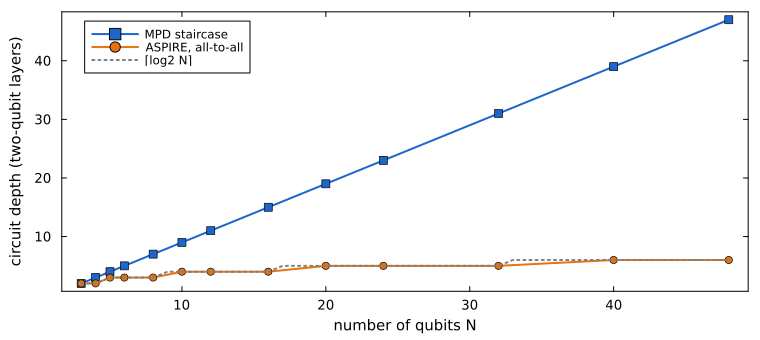

In [9]:
set_max_bond_dim!(256); set_cutoff!(1e-14)
function circuit_depth(supports)
    free = Dict{Int,Int}(); depth = 0
    for (i, j) in supports
        t = max(get(free, i, 0), get(free, j, 0)) + 1
        free[i] = free[j] = t
        depth = max(depth, t)
    end
    return depth
end

sizes = [3, 4, 5, 6, 8, 10, 12, 16, 20, 24, 32, 40, 48]
aspire_layers, aspire_gates, aspire_depth, mpd_depth, mpd_gates, mpd_eps_ghz = Int[], Int[], Int[], Int[], Int[], Float64[]
for N in sizes
    psi = ghz_block_state(N, 1, N)
    cands = candidate_pairs(N)
    cfg = ASPIREConfig(threshold=0.0, relative_threshold=0.0, max_depth=4N, batch_mode=:blossom,
        cost_normalised=false, shortlist=length(cands), matching_max_edges=2 * length(cands))
    run = aspire(psi; config=cfg, pairs=cands)
    @assert run.T[end] < 1e-8
    push!(aspire_layers, run.depth[end]); push!(aspire_gates, run.gates[end])
    push!(aspire_depth, circuit_depth([(g.i, g.j) for g in run.gate_log]))
    circuit = mpd_circuit(psi, 1)
    supports = [Tuple(g.site_numbers) for g in circuit if length(g.site_numbers) == 2]
    push!(mpd_gates, length(supports)); push!(mpd_depth, circuit_depth(supports))
    push!(mpd_eps_ghz, rudolph_infidelity(circuit, psi))
end
println("ASPIRE depth = ceil(log2 N), MPD depth = N - 1, gates = N - 1 for both: ",
    all(aspire_layers .== ceil.(Int, log2.(sizes))) && all(aspire_depth .== aspire_layers) &&
    all(mpd_depth .== sizes .- 1) && all(aspire_gates .== sizes .- 1) && all(mpd_gates .== sizes .- 1))
@printf("largest residual infidelity of the MPD staircase: %.1e\n", maximum(mpd_eps_ghz))
pg = plot(sizes, mpd_depth; color=BLUE, marker=:square, label="MPD staircase",
    xlabel="number of qubits N", ylabel="circuit depth (two-qubit layers)", legend=:topleft)
plot!(pg, sizes, aspire_depth; color=ORANGE, marker=:circle, label="ASPIRE, all-to-all")
plot!(pg, 3:48, ceil.(log2.(3:48)); color=:gray, linestyle=:dot, label="⌈log2 N⌉")
pg

## Quantics Gaussian

A correlated bivariate Gaussian ($\rho=0.6$) on a 32 x 32 grid, stored bit by bit on 10 qubits with the bits of each variable contiguous. The MPD runs in whole staircase layers up to a gate cap set by a saturation rule, and ASPIRE is given the same final gate count. Neither arm is optimised.

In [10]:
set_max_bond_dim!(64); set_cutoff!(1e-10)
n_bits = 5
psi_q = quantics_function_state(2, n_bits; family="gaussian", rho=0.6, ordering=:serial, rng=MersenneTwister(1))
N_q = length(psi_q)
@printf("N = %d, chi = %d, T = %.2f bits\n", N_q, maxlinkdim(psi_q), total_correlation(psi_q))

rule = SaturationRule(gain_per_doubling=1.10, confirm=1.5, floor=1e-10, min_gates_per_site=2.0, max_gates_per_site=10.0)
cap = saturation_gate_cap(rule, N_q)
mpd_q = ran_iter_oall_curve(psi_q; Lmax=cld(cap, N_q - 1), sweeps=0, stop=rule)
mpd_q_eps = 1 .- sqrt.(mpd_q.fid)
budget_q = mpd_q.gates[end]

cfg_q = ASPIREConfig(threshold=0.0, relative_threshold=0.0, max_depth=200, max_gates=budget_q,
    batch_mode=:matching, shortlist=32, cost_normalised=false, accept_only=false, min_objective_gain=-1e6)
aspire_q = aspire(psi_q; config=cfg_q)
aspire_q_eps = aspire_q.product_frame_amplitude_infidelity
@printf("gate cap %d, matched budget %d gates\n", cap, budget_q)
for g in (20, 40, 80, budget_q)
    a, m = curve_infidelity_at(aspire_q.gates, aspire_q_eps, g), curve_infidelity_at(mpd_q.gates[2:end], mpd_q_eps[2:end], g)
    @printf("at %3d gates: MPD %.2e, ASPIRE %.2e, ratio MPD/ASPIRE = %.2f\n", g, m, a, m / a)
end

N = 10, chi = 10, T = 5.02 bits
gate cap 100, matched budget 108 gates
at  20 gates: MPD 1.77e-02, ASPIRE 1.38e-02, ratio MPD/ASPIRE = 1.28
at  40 gates: MPD 8.08e-03, ASPIRE 4.29e-03, ratio MPD/ASPIRE = 1.88
at  80 gates: MPD 3.81e-03, ASPIRE 1.76e-03, ratio MPD/ASPIRE = 2.17
at 108 gates: MPD 2.71e-03, ASPIRE 1.30e-03, ratio MPD/ASPIRE = 2.09


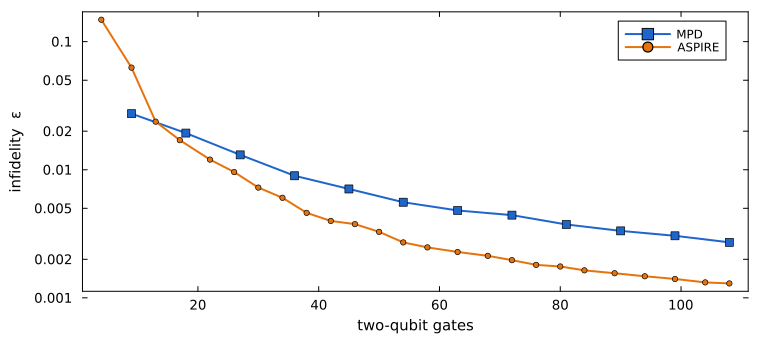

In [11]:
pq = plot(xlabel="two-qubit gates", ylabel="infidelity  ε", yscale=:log10,
    yticks=([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1], ["0.001", "0.002", "0.005", "0.01", "0.02", "0.05", "0.1"]), legend=:topright)
plot!(pq, mpd_q.gates[2:end], mpd_q_eps[2:end]; color=BLUE, marker=:square, label="MPD")
plot!(pq, aspire_q.gates[2:end], aspire_q_eps[2:end]; color=ORANGE, marker=:circle, markersize=3, label="ASPIRE")
pq

## T-count

`t_count` decomposes each two-qubit gate into three CNOTs and single-qubit rotations, fuses adjacent rotations and charges each synthesis call a T count. Example for three nearest-neighbour gates on four qubits.

In [12]:
sites4 = siteinds("S=1/2", 4)
rng = MersenneTwister(7)
haar_chain = MPSCircuits.UnitaryGate[MPSCircuits.UnitaryGate(two_qubit_gate(haar_unitary(4, rng), sites4[i], sites4[i + 1])) for i in 1:3]
cnot_chain = MPSCircuits.UnitaryGate[MPSCircuits.UnitaryGate(two_qubit_gate(ComplexF64[1 0 0 0; 0 1 0 0; 0 0 0 1; 0 0 1 0], sites4[i], sites4[i + 1])) for i in 1:3]
@printf("CNOT chain:            rotations %d, T-count %.0f\n", rotation_count(cnot_chain), t_count(cnot_chain; epsilon=1e-3))
@printf("3 Haar-random gates:   rotations %d\n", rotation_count(haar_chain))
for eps in (1e-2, 1e-3, 1e-6)
    @printf("  epsilon per call %.0e: GRIDSYNTH %7.1f   TRASYN %7.1f\n", eps,
        t_count(haar_chain; epsilon=eps, model=GRIDSYNTH), t_count(haar_chain; epsilon=eps, model=TRASYN))
end

CNOT chain:            rotations 0, T-count 0
3 Haar-random gates:   rotations 35
  epsilon per call 1e-02: GRIDSYNTH   774.2   TRASYN   420.3
  epsilon per call 1e-03: GRIDSYNTH  1129.3   TRASYN   613.0
  epsilon per call 1e-06: GRIDSYNTH  2194.5   TRASYN  1191.3
